In [181]:
import jax
import gemlib
import jax.numpy as jnp
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

import numpy as np
import seaborn as sns
import pandas as pd
import tensorflow_probability.substrates.jax as tfp
import xarray as xr
import scipy as sp

from scipy import stats
from scipy.stats import gamma, norm
from typing import NamedTuple
from jax.typing import ArrayLike
from gemlib.deterministic import ode_model
from gemlib.distributions import DiscreteTimeStateTransitionModel
from gemlib.mcmc import mcmc, rwmh, adaptive_rwmh, hmc, transform_sampling_algorithm

%matplotlib inline
tfd = tfp.distributions
tfb = tfp.bijectors

jax.config.update("jax_enable_x64", True)
DTYPE=jnp.float64

sns.set_theme()

In [183]:
# --- Spain Data ---

df = pd.read_csv("spain_ag.csv")

df["ISO_WEEKSTARTDATE"] = pd.to_datetime(df['ISO_WEEKSTARTDATE'], format='%Y-%m-%d')    # reformatting
df = df.rename(columns = {"ISO_WEEKSTARTDATE": "week_start",
                          "ILI_CASE" : "positive"})

# - TEMP ONLY X SEASONS
last_5_seasons = sorted(df["season"].dropna().unique())[-5:]
df_last3 = (df[df["season"].isin(last_5_seasons)].copy().reset_index(drop=True))
# -

obs_cases_real = df_last3['positive'].values    # extract cases

valid = np.isfinite(obs_cases_real)    # create index for observations only (ignores NA)

# -----

In [184]:
# --- Season Boundaries ---

def get_season_boundaries(start_year, n_seasons, burn_in_seasons):
    
    """
    Calculate the day boundaries of influenza seasons.
    
    Each season runs from Monday of ISO week 40 to the start of week 40 in the following year.

    Parameters:
        start_year        : Calendar year in which the first *observed* season starts.
        n_seasons         : Number of observed seasons.
        burn_in_seasons   : Number of preceding seasons simulated as burn-in.

    Returns:
        season_boundaries : Array of the season boundaries (days) since the start of the simulation.
                            Includes the initial boundary and final endpoint.
    """

    first_year = start_year - burn_in_seasons    # first year of whole simulation

    # Find Monday W40 for each season inc. final endpoint
    season_starts = [pd.Timestamp.fromisocalendar(year, 40, 1) 
                     for year in range(first_year, start_year + n_seasons + 1)]

    # Convert calendar dates into days since the first day
    season_boundaries = np.array([(date - season_starts[0]).days 
                                   for date in season_starts])

    return jnp.asarray(season_boundaries, dtype=DTYPE)

# -----

In [185]:
# --- Construct Omega_s Vector ---

def make_omega_s(omega0, W_s, total_seasons, burn_in_seasons):
    
    """
    Construct the immunity-loss rate for each influenza season.

    Burn-in seasons use the baseline rate omega0.
    Observed seasons use omega0 plus a season-specific random effect.

    Parameters:
        omega0          : Baseline immunity-loss rate.
        W_s             : Random effects for the observed seasons (log-scale).
        total_seasons   : Total seasons, including burn-in.
        burn_in_seasons : Number of burn-in seasons.

    Returns:
        omega_s         : Immunity-loss rate for each season.
    """
    
    omega_s = []    # storage
    
    for s in range(total_seasons):
        
        if s < burn_in_seasons:
            # Burn-in: use just baseline
            omega_s.append(omega0)
            
        else:
            # Observed seasons: use baseline + random effect
            idx = s - burn_in_seasons
            omega_s.append(omega0 * jnp.exp(W_s[idx])) 
    
    return jnp.array(omega_s, dtype=DTYPE)

# -----

In [186]:
# --- ODE Model ---

def seirs_beta_t_omega_s_ode_model(beta, sigma, gamma, omega_s, amp, phase, season_boundaries):

    def se_rate(t, state):
        seasonal_term = amp * jnp.cos(2 * jnp.pi * t / 365 - phase)
        beta_t = beta * jnp.exp(seasonal_term)
        return beta_t * state[:, 2] / state.sum(axis=-1)
        
    def ei_rate(t, state):
        return sigma
    
    def ir_rate(t, state):
        return gamma

    def rs_rate(t, state):
        t_index = jnp.searchsorted(season_boundaries, t, side="right") - 1
        return omega_s[t_index]

    return ode_model(transition_rate_fn = [se_rate, ei_rate, ir_rate, rs_rate],
                     initial_state = initial_state,
                     incidence_matrix = incidence_matrix,
                     num_steps = num_steps,
                     initial_time = 0.0,
                     time_delta = 1.0)

# -----

In [187]:
# --- Model Function WEEKLY AG ---

@tfd.JointDistributionCoroutineAutoBatched
def model():

# - Priors:
    beta = yield tfd.Gamma(concentration=DTYPE(300.0), rate=DTYPE(1000.0), name="beta")
    sigma = DTYPE(0.5)
    gamma = DTYPE(0.2)
    omega0 = yield tfd.Gamma(concentration=DTYPE(1.0), rate=DTYPE(180.0), name="omega0")
    W_s_SD = DTYPE(1)
    W_s = yield tfd.Sample(tfd.Normal(loc=DTYPE(0.0), scale=W_s_SD), sample_shape=5, name="W_s")
    amp = DTYPE(-0.2)
    phase = DTYPE(-2.0)

# - Model:
    # Construct seasonal omega
    omega_s = make_omega_s(omega0, W_s, n_season + n_burn_in_season, n_burn_in_season)

    seirs = seirs_beta_t_omega_s_ode_model(beta, sigma, gamma, omega_s, amp, phase, season_bounds)

    states_burn = seirs.states[burn_in_index:]
    
    # Expected cases
    daily_lmda = alpha * sigma * states_burn[:, 0, 1]           # daily exp. cases
    weekly_lmda = jnp.sum(daily_lmda.reshape(-1, 7), axis=1)    # weekly exp. cases
    
    weekly_lmda_valid = weekly_lmda[valid]    # keep only weeks with observations for the likelihood
    
    yield tfd.Poisson(rate=weekly_lmda_valid, name="obs_cases")
    
# -----

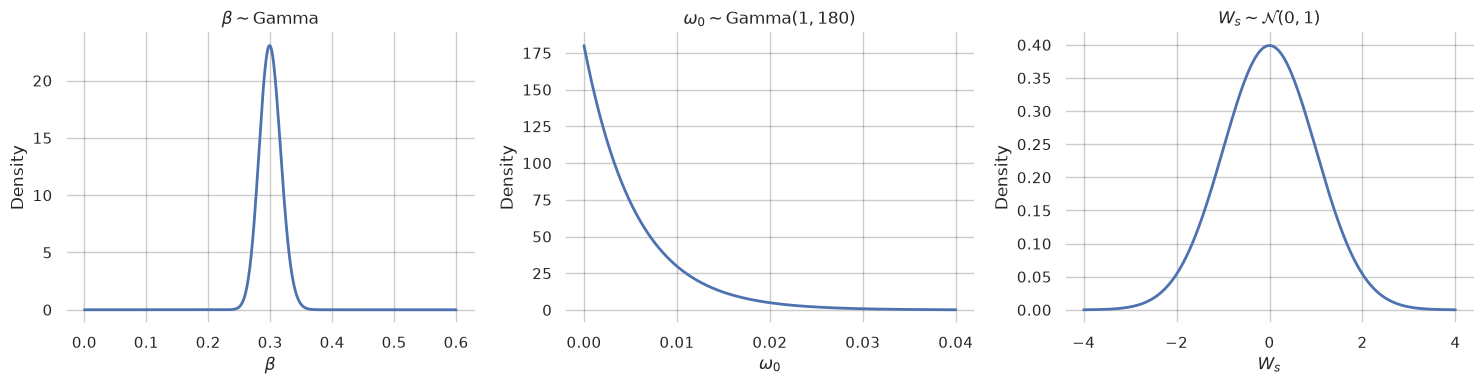

In [188]:
# --- Priors ---

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# - Beta prior:
x = np.linspace(0, 0.6, 500)
axes[0].plot(x, gamma.pdf(x, a=300, scale=1/1000), linewidth=2)
axes[0].set_title(r'$\beta \sim \mathrm{Gamma}$')
axes[0].set_xlabel(r'$\beta$')

# - Omega0 prior:
x = np.linspace(0, 0.04, 500)
axes[1].plot(x, gamma.pdf(x, a=1, scale=1/180), linewidth=2)
axes[1].set_title(r'$\omega_0 \sim \mathrm{Gamma}(1, 180)$')
axes[1].set_xlabel(r'$\omega_0$')

# - W_s prior:
x = np.linspace(-4, 4, 500)
axes[2].plot(x, norm.pdf(x, loc=0, scale=1), linewidth=2)
axes[2].set_title(r'$W_s \sim \mathcal{N}(0, 1)$')
axes[2].set_xlabel(r'$W_s$')

# - Formatting:
for ax in axes:
    ax.set_ylabel('Density')
    ax.grid(True, color='black', alpha=0.2)
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.tight_layout()
plt.show()

# -----

In [189]:
# --- Kernel Setup ARWMH ---

kernel = transform_sampling_algorithm(
    bijectors=[tfb.Exp(),        # beta
               tfb.Exp(),        # omega0
               tfb.Identity()    # W_s
    ],
    sampling_algorithm=adaptive_rwmh(initial_scale=1))

# -----

In [190]:
# --- Kernel Setup HMC ---

kernel = transform_sampling_algorithm(
    bijectors=[tfb.Exp(),        # beta
               tfb.Exp(),        # omega0
               tfb.Identity()    # W_s
    ],
    sampling_algorithm=hmc(step_size=0.1, num_leapfrog_steps=16))

# -----

In [201]:
# --- Fixed Inputs ---
# Try make everything 64 float?

# Incidence Matrix Setup
# - Compartments: S, E, I, R
# - Transitions: S -> E, E -> I, I -> R, R -> S
incidence_matrix = np.array([
    [-1,  0,  0,  1],  # S
    [ 1, -1,  0,  0],  # E
    [ 0,  1, -1,  0],  # I
    [ 0,  0,  1, -1]   # R
], dtype=np.float32)


# Initial State
initial_state = np.array([[46999999, 0, 1, 0]], dtype=DTYPE)
popsize = jnp.asarray(47000000, dtype=DTYPE)


# Fixed parameters
sigma = jnp.asarray(0.5, dtype=DTYPE)
alpha = jnp.asarray(0.0025, dtype=DTYPE)


# Season Boundaries
n_season = 5
n_burn_in_season = 20

season_bounds = get_season_boundaries(2012, n_season, n_burn_in_season)
num_steps = int(season_bounds[-1])


# Log Omega_s Setup
sim_omega0 = jnp.asarray(1 / 180, dtype=DTYPE)
#sim_W_s = jnp.array([-0.1, 0.1, 0.5, 0.3, -0.2], dtype=jnp.float32)
sim_W_s = jnp.array([0, 0, 0, 0, 0], dtype=DTYPE)

sim_omega_s = make_omega_s(sim_omega0, sim_W_s, n_season + n_burn_in_season, n_burn_in_season)

# -----

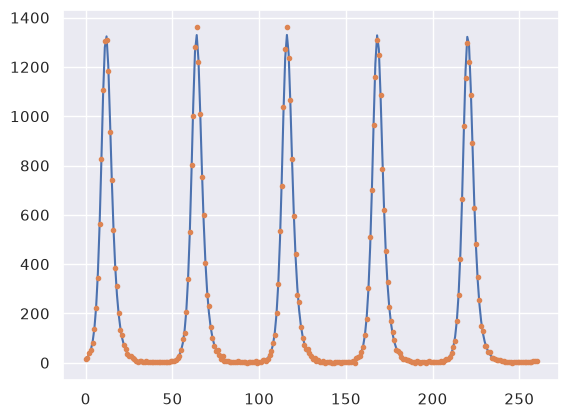

In [202]:
# --- Simulate Data ---

sim = seirs_beta_t_omega_s_ode_model(beta=0.3, sigma=1/2, gamma=1/5, omega_s=sim_omega_s, amp=-0.2, phase=-2, season_boundaries=season_bounds)

burn_in_index = int(season_bounds[n_burn_in_season])

times_burn = sim.times[burn_in_index:]
states_burn = sim.states[burn_in_index:]

sim_df = pd.DataFrame({
    "time": times_burn - season_bounds[n_burn_in_season],
    "S": states_burn[:, 0, 0],
    "E": states_burn[:, 0, 1],
    "I": states_burn[:, 0, 2],
    "R": states_burn[:, 0, 3]
})
 
# Aggregate simulation to weekly
sim_df["daily_incidence"] = sigma * sim_df["E"]

# Create weekly index
sim_df["week"] = (sim_df["time"] // 7).astype(int)

# Aggregate daily incidence into weekly totals
sim_weekly_df = (sim_df.groupby("week", as_index=False)
                .agg(incidence=("daily_incidence", "sum"),
                     S=("S", "last"),
                     E=("E", "last"),
                     I=("I", "last"),
                     R=("R", "last")))


# Expected and Observed Cases
expected_cases = sigma * sim_weekly_df["E"] * alpha

np.random.seed(123)
obs_cases = np.random.poisson(lam = expected_cases)

plt.plot(sim_weekly_df["week"], expected_cases)
plt.plot(sim_weekly_df["week"], obs_cases, '.')

# -----

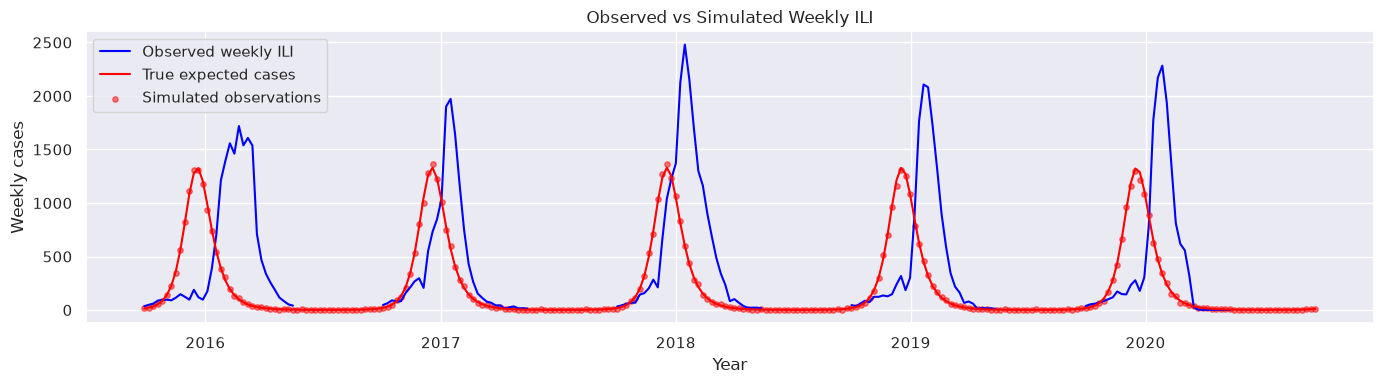

In [203]:
fig, ax = plt.subplots(figsize=(14, 4))

# Real weekly observations
ax.plot(
    df_last3['week_start'],
    df_last3['positive'],
    label='Observed weekly ILI',
    color='blue'
)

# Simulated expected cases
ax.plot(
    df_last3['week_start'],
    expected_cases,
    label='True expected cases',
    color='red'
)

# Simulated observations
ax.scatter(
    df_last3['week_start'],
    obs_cases,
    label='Simulated observations',
    color='red',
    alpha=0.5,
    s=15
)

ax.set_xlabel('Year')
ax.set_ylabel('Weekly cases')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(True)
ax.legend()

plt.title('Observed vs Simulated Weekly ILI')
plt.tight_layout()
plt.show()

In [204]:
pinned_model = model.experimental_pin(obs_cases=obs_cases_real[valid])    # real data, only valid week obs.

init_pos = pinned_model.sample_unpinned(seed=jax.random.key(456))

log_prob = pinned_model.log_prob(init_pos)
print(log_prob)

-365315.3122512902


In [205]:
# Check gradient working?
grad = jax.grad(pinned_model.log_prob)(init_pos)
grad

UnexpectedTracerError: Encountered an unexpected tracer. A function transformed by JAX had a side effect, allowing for a reference to an intermediate value with type float64[] wrapped in a LinearizeTracer to escape the scope of the transformation.
JAX transformations require that functions explicitly return their outputs, and disallow saving intermediate values to global state.
To catch the leak earlier, try setting the environment variable JAX_CHECK_TRACER_LEAKS or using the `jax.checking_leaks` context manager.
See https://docs.jax.dev/en/latest/errors.html#jax.errors.UnexpectedTracerError

In [206]:
nits = 50

samples, info = mcmc(
    num_samples=nits,
    sampling_algorithm=kernel,
    target_log_density_fn=pinned_model.log_prob,
    initial_position=init_pos,
    seed=jax.random.key(101))

_ = jax.block_until_ready(samples)

UnexpectedTracerError: Encountered an unexpected tracer. A function transformed by JAX had a side effect, allowing for a reference to an intermediate value with type float64[] wrapped in a LinearizeTracer to escape the scope of the transformation.
JAX transformations require that functions explicitly return their outputs, and disallow saving intermediate values to global state.
To catch the leak earlier, try setting the environment variable JAX_CHECK_TRACER_LEAKS or using the `jax.checking_leaks` context manager.
See https://docs.jax.dev/en/latest/errors.html#jax.errors.UnexpectedTracerError

In [ ]:
parameter_names = ["beta", "omega", "W_s"]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for s, n, a in zip(samples, parameter_names, axes):
    a.plot(s, linewidth=0.5)
    a.set_ylabel(n)
    a.grid(alpha=0.3)

axes[-1].set_xlabel("Iteration")

plt.suptitle("Traceplots - SEIRS Model")
plt.tight_layout()
plt.show()

print(np.mean(info.is_accepted))

In [56]:
burn_in = 40000 

samples_burned = samples._replace(
    beta=samples.beta[burn_in:],
    omega0=samples.omega0[burn_in:],
    W_s=samples.W_s[burn_in:]
)

In [ ]:
# Traceplots
parameter_names = ["beta", "omega0", "W_s"]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for s, n, a in zip(
    [samples_burned.beta, samples_burned.omega0, samples_burned.W_s],
    parameter_names,
    axes
):
    if n == "W_s":
        for i in range(s.shape[-1]):
            a.plot(s[:, i], linewidth=0.5, label=f"W_{i+1}")
        a.legend()
    else:
        a.plot(s, linewidth=0.5)

    a.set_ylabel(n)
    a.grid(alpha=0.3)

axes[-1].set_xlabel("Iteration")

plt.suptitle("Traceplots - SEIRS Model (Burn-in Removed)")
plt.tight_layout()
plt.show()

In [ ]:
# --- True vs Median Parameters ---

beta_med = np.median(samples_burned.beta, axis=0)
omega0_med = np.median(samples_burned.omega0, axis=0)
W_s_med = np.median(samples_burned.W_s, axis=0)

print("-----")
print("True vs median parameter values:")

print(f"beta:   {0.3:.4f}, {beta_med:.4f}")
print(f"omega0: {1/180:.4f}, {omega0_med:.4f}")

for i, (true, med) in enumerate(zip(sim_W_s, W_s_med), start=1):
    print(f"W_{i}:    {true:.4f}, {med:.4f}")

print("-----")

# -----

In [44]:
# --- Reconstruct omega_s ---
omega_s_med = make_omega_s(
    omega0_med,
    W_s_med,
    n_season + n_burn_in_season,
    n_burn_in_season
)

# --- Simulate using posterior median parameters ---
fit = seirs_beta_t_omega_s_ode_model(
    beta=beta_med,
    sigma=0.5,
    gamma=0.2,
    omega_s=omega_s_med,
    amp=-0.2,
    phase=-2,
    season_boundaries=season_bounds
)

# --- Remove burn-in ---
fit_states_burn = fit.states[burn_in_index:]

fit_df = pd.DataFrame({
    "time": fit.times[burn_in_index:] - season_bounds[n_burn_in_season],
    "S": fit_states_burn[:, 0, 0],
    "E": fit_states_burn[:, 0, 1],
    "I": fit_states_burn[:, 0, 2],
    "R": fit_states_burn[:, 0, 3]
})

# --- Calculate daily expected cases ---
fit_df["daily_expected_cases"] = alpha * 0.5 * fit_df["E"]

# --- Assign weeks ---
fit_df["week"] = (fit_df["time"] // 7).astype(int)

# --- Aggregate to weekly ---
fit_weekly_df = (
    fit_df.groupby("week", as_index=False)
    .agg(
        S=("S", "last"),
        E=("E", "last"),
        I=("I", "last"),
        R=("R", "last"),
        fitted_expected_cases=("daily_expected_cases", "sum")
    )
)

# --- Simulate Poisson observations (optional) ---
fit_weekly_df["simulated_cases"] = np.random.poisson(
    fit_weekly_df["fitted_expected_cases"]
)

In [ ]:
plt.figure(figsize=(13, 5))

# Observed cases
plt.plot(
    df_last3['week_start'],
    df_last3['positive'],
    label="Observed cases",
    linewidth=1.8,
    color="#4F9269"
)

# Fitted expected cases
plt.plot(
    df_last3['week_start'],
    fit_weekly_df['fitted_expected_cases'],
    label="Fitted expected cases (posterior medians)",
    linewidth=2,
    linestyle="--",
    color="#9B5CC1"
)

plt.xlabel("Date")
plt.ylabel("Positive cases")
plt.title("Observed vs fitted SEIRS model")
plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

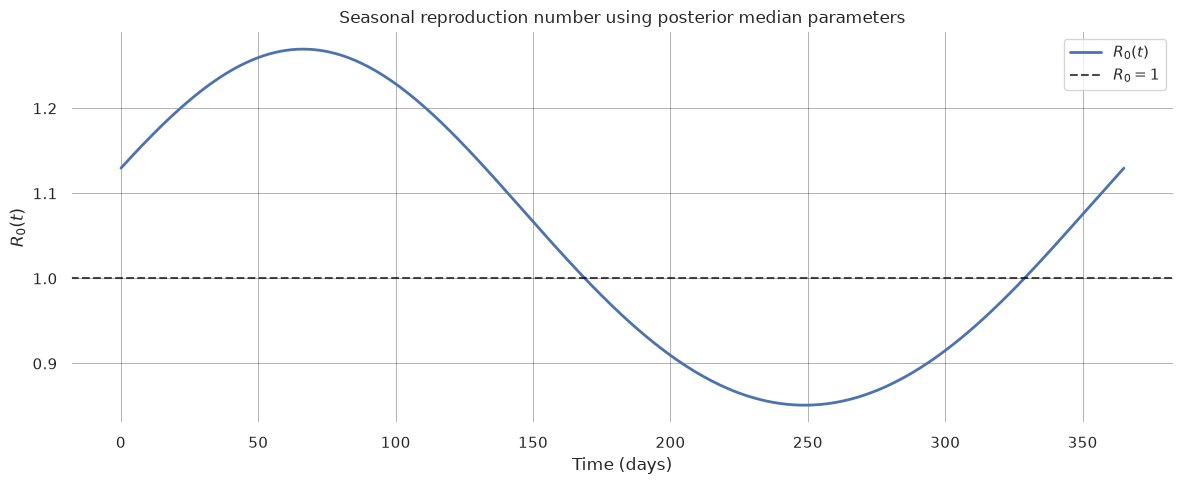

In [46]:
# Time over one year
t = np.linspace(0, 365, 366)

# Parameters
gamma = 1/5
amp = -0.2
phase = -2

# Time-varying beta
beta_t = beta_med * np.exp(
    amp * np.cos(2 * np.pi * t / 365 - phase)
)

# Time-varying R0
R0_t = beta_t / gamma

# Plot
plt.figure(figsize=(12, 5))

plt.plot(t, R0_t, linewidth=2, label=r"$R_0(t)$")
plt.axhline(1, color="black", linestyle="--", alpha=0.7, label=r"$R_0=1$")

plt.xlabel("Time (days)")
plt.ylabel(r"$R_0(t)$")
plt.title("Seasonal reproduction number using posterior median parameters")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
# Test Only Beta and Omega

In [211]:
# --- Fixed Inputs ---
# Try make everything 64 float?

# Incidence Matrix Setup
# - Compartments: S, E, I, R
# - Transitions: S -> E, E -> I, I -> R, R -> S
incidence_matrix = np.array([
    [-1,  0,  0,  1],  # S
    [ 1, -1,  0,  0],  # E
    [ 0,  1, -1,  0],  # I
    [ 0,  0,  1, -1]   # R
], dtype=np.float32)


# Initial State
initial_state = np.array([[46999999, 0, 1, 0]], dtype=DTYPE)
popsize = jnp.asarray(47000000, dtype=DTYPE)


# Fixed parameters
sigma = jnp.asarray(0.5, dtype=DTYPE)
alpha = jnp.asarray(0.0025, dtype=DTYPE)


# Season Boundaries
n_season = 5
n_burn_in_season = 20

season_bounds = get_season_boundaries(2012, n_season, n_burn_in_season)
num_steps = int(season_bounds[-1])

# -----

In [283]:
# --- ODE Model ---
# Try make everything 64 float?

# ODE Function Setup
def seirs_beta_t_ode_model(beta, sigma, gamma, omega, amp, phase):

    def se_rate(t, state):
        seasonal_term = amp * jnp.cos(2 * np.pi * t / 365 - phase)
        beta_t = beta * jnp.exp(seasonal_term)
        return beta_t * state[:, 2] / state.sum(axis=-1)

        
    def ei_rate(t, state):
        return sigma

    def ir_rate(t, state):
        return gamma

    def rs_rate(t, state):
        return omega

    return ode_model(transition_rate_fn = [se_rate, ei_rate, ir_rate, rs_rate],
                     initial_state = initial_state,
                     incidence_matrix = incidence_matrix,
                     num_steps = num_steps,
                     initial_time = 0.0,
                     time_delta = 1.0)

# -----

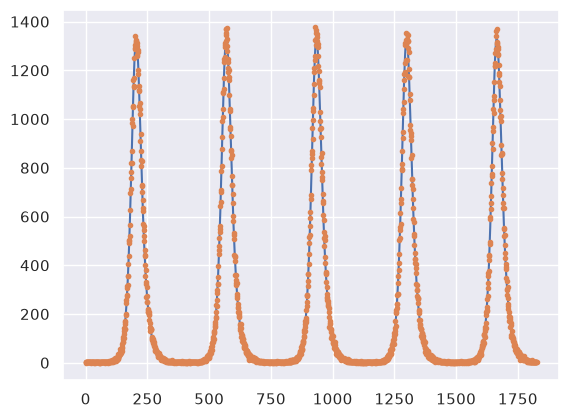

In [284]:
# --- Simulate Data ---

sim = seirs_beta_t_ode_model(beta=0.3, sigma=1/2, gamma=1/5, omega=1/180, amp=-0.2, phase=0)

burn_in_index = int(season_bounds[n_burn_in_season])

times_burn = sim.times[burn_in_index:]
states_burn = sim.states[burn_in_index:]

sim_df = pd.DataFrame({
    "time": times_burn - season_bounds[n_burn_in_season],
    "S": states_burn[:, 0, 0],
    "E": states_burn[:, 0, 1],
    "I": states_burn[:, 0, 2],
    "R": states_burn[:, 0, 3]
})
 
expected_cases = sigma * sim_df["E"] * alpha

np.random.seed(123)
obs_cases = np.random.poisson(lam = expected_cases)

plt.plot(sim_df["time"], expected_cases)
plt.plot(sim_df["time"], obs_cases, '.')

# -----

In [285]:
# --- Model Function ---

@tfd.JointDistributionCoroutineAutoBatched
def model():

# - Priors:
    beta = yield tfd.Gamma(concentration=DTYPE(300.0), rate=DTYPE(1000.0), name="beta")
    sigma = DTYPE(0.5)
    gamma = DTYPE(0.2)
    omega = yield tfd.Gamma(concentration=DTYPE(1.0), rate=DTYPE(180.0), name="omega")
    amp = DTYPE(-0.2)
    phase = DTYPE(0.0)

# - Model
    seirs = seirs_beta_t_ode_model(beta, sigma, gamma, omega, amp, phase)

    states_burn = seirs.states[burn_in_index:]

    lmda = alpha * sigma * states_burn[:, 0, 1]    # alpha * sigma * E

    yield tfd.Poisson(rate = lmda, name = "obs_cases")
    
# -----

In [286]:
pinned_model = model.experimental_pin(obs_cases=obs_cases)

In [287]:
init_pos = pinned_model.sample_unpinned(seed=jax.random.key(456))
init_pos

StructTuple(
  beta=Array(0.30241095, dtype=float64),
  omega=Array(0.01003378, dtype=float64)
)

In [288]:
kernel = transform_sampling_algorithm(
    bijectors=[tfb.Exp()]*2,
    sampling_algorithm=hmc(step_size=0.1, num_leapfrog_steps=16))   # try adaptive HMC

In [289]:
def run_chain(x0):
    samples, info = mcmc(
        num_samples=10,
        sampling_algorithm=kernel,
        target_log_density_fn=pinned_model.log_prob,
        initial_position=x0,
        seed=jax.random.key(101),
    )
    return samples, info

In [290]:
samples_mwg, results_mwg = run_chain(init_pos)

UnexpectedTracerError: Encountered an unexpected tracer. A function transformed by JAX had a side effect, allowing for a reference to an intermediate value with type float64[] wrapped in a LinearizeTracer to escape the scope of the transformation.
JAX transformations require that functions explicitly return their outputs, and disallow saving intermediate values to global state.
To catch the leak earlier, try setting the environment variable JAX_CHECK_TRACER_LEAKS or using the `jax.checking_leaks` context manager.
See https://docs.jax.dev/en/latest/errors.html#jax.errors.UnexpectedTracerError

In [291]:
lp = pinned_model.log_prob(init_pos)
print(lp)

-531236.4023315533


In [292]:
grad_fn = jax.grad(pinned_model.log_prob)
grads = grad_fn(init_pos)

print(grads)

UnexpectedTracerError: Encountered an unexpected tracer. A function transformed by JAX had a side effect, allowing for a reference to an intermediate value with type float64[] wrapped in a LinearizeTracer to escape the scope of the transformation.
JAX transformations require that functions explicitly return their outputs, and disallow saving intermediate values to global state.
To catch the leak earlier, try setting the environment variable JAX_CHECK_TRACER_LEAKS or using the `jax.checking_leaks` context manager.
See https://docs.jax.dev/en/latest/errors.html#jax.errors.UnexpectedTracerError